<a href="https://colab.research.google.com/github/Devang1812/py/blob/master/Titanic_EDA_Streamlit_Repaired.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Titanic EDA and Streamlit Dashboard (Google Colab)

This is a clean replacement for the original notebook. It removes unrelated Customer Churn cells, fixes data-cleaning and plotting issues, and creates a separate Streamlit app.

**Dataset:** The notebook first tries to load `titanic.csv` if you upload it; otherwise it uses Seaborn's built-in Titanic sample. The dashboard also supports an uploaded CSV.

## 1. Install dependencies

In [1]:
!pip -q install pandas numpy matplotlib seaborn plotly streamlit

## 2. Load and inspect the Titanic dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# If titanic.csv exists in the Colab working directory, use it.
# Otherwise, use Seaborn's built-in sample dataset.
if Path("titanic.csv").exists():
    df = pd.read_csv("titanic.csv")
else:
    df = sns.load_dataset("titanic")

print("Shape:", df.shape)
display(df.head())
display(df.tail())
display(df.info())
display(df.describe(include="all").T)


Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data quality checks and cleaning

In [3]:
# Standardize column names for consistent access
df.columns = df.columns.astype(str).str.strip()

print("Missing values before cleaning:")
display(df.isna().sum().sort_values(ascending=False))

# Drop Cabin only when present; it is very sparse in the Kaggle dataset.
if "Cabin" in df.columns:
    df = df.drop(columns=["Cabin"])

# Fill numeric Age with its median (only if Age exists).
if "Age" in df.columns:
    df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill Embarked with its mode (only if the column exists and has a mode).
if "Embarked" in df.columns and not df["Embarked"].mode(dropna=True).empty:
    df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode(dropna=True).iloc[0])

# Do not use dropna() without assignment: report remaining missing values instead.
print("Missing values after selected cleaning:")
display(df.isna().sum().sort_values(ascending=False))
print("Duplicate rows:", df.duplicated().sum())


Missing values before cleaning:


,0
deck,688
age,177
embarked,2
embark_town,2
sex,0
pclass,0
survived,0
fare,0
parch,0
sibsp,0


Missing values after selected cleaning:


,0
deck,688
age,177
embarked,2
embark_town,2
sex,0
pclass,0
survived,0
fare,0
parch,0
sibsp,0


Duplicate rows: 107


## 4. Univariate analysis

In [4]:
if "Survived" in df.columns:
    survival_counts = df["Survived"].value_counts().reindex([0, 1], fill_value=0)
    plt.figure(figsize=(5, 4))
    plt.pie(survival_counts, labels=["Did not survive", "Survived"],
            autopct="%1.1f%%", startangle=90)
    plt.title("Passenger survival distribution")
    plt.show()

if "Age" in df.columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(df["Age"].dropna(), bins=25, kde=True)
    plt.xlabel("Age")
    plt.ylabel("Passenger count")
    plt.title("Age distribution")
    plt.show()


## 5. Bivariate analysis

In [5]:
if {"Sex", "Survived"}.issubset(df.columns):
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="Sex", hue="Survived")
    plt.title("Survival count by gender")
    plt.show()

if {"Pclass", "Survived"}.issubset(df.columns):
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="Pclass", hue="Survived")
    plt.title("Survival count by passenger class")
    plt.show()

if {"Age", "Fare"}.issubset(df.columns):
    plt.figure(figsize=(7, 4))
    sns.scatterplot(data=df, x="Age", y="Fare", hue="Survived" if "Survived" in df else None)
    plt.title("Age vs fare")
    plt.show()


## 6. Multivariate analysis and correlation

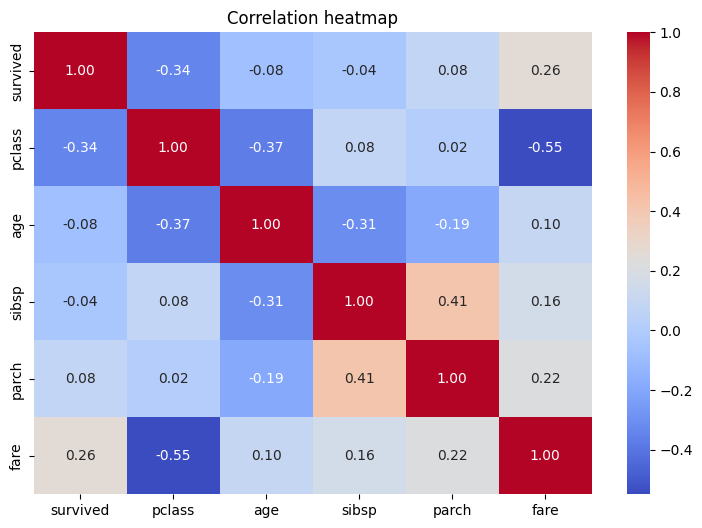

In [6]:
# Convert categorical Sex to numeric in a separate analysis copy.
# This avoids changing the original display/data values.
analysis_df = df.copy()
if "Sex" in analysis_df.columns:
    analysis_df["Sex"] = analysis_df["Sex"].map({"male": 0, "female": 1})

numeric_df = analysis_df.select_dtypes(include=np.number)
if not numeric_df.empty:
    plt.figure(figsize=(9, 6))
    sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation heatmap")
    plt.show()

if {"Age", "Fare", "Survived"}.issubset(df.columns):
    sns.pairplot(df[["Age", "Fare", "Survived"]].dropna(),
                 hue="Survived", corner=True)
    plt.show()


## 7. Optional profiling report

In [7]:
# Optional: install and run ydata-profiling only if you need a detailed HTML report.
# !pip -q install ydata-profiling
# from ydata_profiling import ProfileReport
# profile = ProfileReport(df, title="Titanic EDA Report", explorative=True)
# profile.to_file("titanic_eda_report.html")


## 8. Create the Streamlit application

This cell writes a standalone file named `titanic_streamlit_app.py`. The app accepts either Kaggle-style columns (`Survived`, `Sex`, `Pclass`, `Age`, `Fare`) or Seaborn-style lowercase columns.

In [11]:
%%writefile titanic_streamlit_app.py
import streamlit as st
import pandas as pd
import seaborn as sns
import plotly.express as px

st.set_page_config(page_title="Titanic Survival Dashboard", page_icon="🚢", layout="wide")

REQUIRED = {"survived", "sex", "pclass", "age", "fare"}

@st.cache_data
def load_default_data():
    """Load the Titanic sample dataset bundled with Seaborn."""
    return sns.load_dataset("titanic")

def prepare_data(raw):
    """Normalize Kaggle and Seaborn column names and validate required fields."""
    df = raw.copy()
    df.columns = (
        df.columns.astype(str).str.strip().str.lower()
        .str.replace(r"[\s\-]+", "_", regex=True)
    )
    aliases = {
        "gender": "sex",
        "passenger_class": "pclass",
    }
    df = df.rename(columns={k: v for k, v in aliases.items() if k in df.columns})

    missing = REQUIRED - set(df.columns)
    if missing:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing))}. "
            "Expected Survived, Sex, Pclass, Age and Fare (or equivalent lowercase names)."
        )

    for col in ("survived", "pclass", "age", "fare"):
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df["sex"] = df["sex"].astype("string").str.strip().str.lower()
    df = df.dropna(subset=["survived", "pclass", "sex"]).copy()
    df = df[df["survived"].isin([0, 1]) & df["pclass"].isin([1, 2, 3])]
    df["survived"] = df["survived"].astype(int)
    df["pclass"] = df["pclass"].astype(int)
    df["survival_status"] = df["survived"].map({0: "Did not survive", 1: "Survived"})
    return df

st.title("🚢 Titanic Survival Dashboard")
st.caption("Explore passenger outcomes by gender, passenger class, age and fare.")

st.sidebar.header("Dataset")
uploaded = st.sidebar.file_uploader("Upload a Titanic CSV (optional)", type=["csv"])
try:
    raw_df = pd.read_csv(uploaded) if uploaded is not None else load_default_data()
    df = prepare_data(raw_df)
except Exception as exc:
    st.error(f"Unable to load the dataset: {exc}")
    st.stop()

st.sidebar.caption("Using uploaded CSV" if uploaded is not None else "Using Seaborn Titanic sample")
st.sidebar.header("Filters")

genders = sorted(df["sex"].dropna().unique().tolist())
classes = sorted(df["pclass"].dropna().unique().tolist())
selected_genders = st.sidebar.multiselect("Gender", genders, default=genders)
selected_classes = st.sidebar.multiselect("Passenger class", classes, default=classes)

age_values = df["age"].dropna()
if not age_values.empty:
    age_low, age_high = float(age_values.min()), float(age_values.max())
    if age_low == age_high:
        age_range = (age_low, age_high)
    else:
        age_range = st.sidebar.slider(
            "Age range", min_value=age_low, max_value=age_high,
            value=(age_low, age_high)
        )
else:
    age_range = None
    st.sidebar.info("Age filter unavailable: no valid age values.")

mask = df["sex"].isin(selected_genders) & df["pclass"].isin(selected_classes)
if age_range is not None:
    mask &= df["age"].isna() | df["age"].between(*age_range)
filtered = df.loc[mask].copy()

if filtered.empty:
    st.warning("No passengers match these filters. Change the selections in the sidebar.")
    st.stop()

total = len(filtered)
survivors = int(filtered["survived"].sum())
non_survivors = total - survivors
rate = survivors / total * 100 if total else 0

m1, m2, m3, m4 = st.columns(4)
m1.metric("Total passengers", f"{total:,}")
m2.metric("Survived", f"{survivors:,}")
m3.metric("Did not survive", f"{non_survivors:,}")
m4.metric("Survival rate", f"{rate:.1f}%")
st.divider()

left, right = st.columns(2)
with left:
    st.subheader("Survival distribution")
    counts = (filtered["survival_status"].value_counts()
              .rename_axis("Status").reset_index(name="Passengers"))
    fig = px.pie(counts, names="Status", values="Passengers", hole=0.45)
    st.plotly_chart(fig, use_container_width=True)

with right:
    st.subheader("Survival rate by gender")
    gender_stats = filtered.groupby("sex", as_index=False).agg(
        survival_rate=("survived", "mean"), passengers=("survived", "size")
    )
    gender_stats["survival_rate"] *= 100
    fig = px.bar(gender_stats, x="sex", y="survival_rate", color="sex",
                 text=gender_stats["survival_rate"].map(lambda x: f"{x:.1f}%"),
                 labels={"sex": "Gender", "survival_rate": "Survival rate (%)"})
    fig.update_layout(showlegend=False, yaxis_range=[0, 100])
    st.plotly_chart(fig, use_container_width=True)

left, right = st.columns(2)
with left:
    st.subheader("Survival rate by passenger class")
    class_stats = filtered.groupby("pclass", as_index=False).agg(
        survival_rate=("survived", "mean"), passengers=("survived", "size")
    )
    class_stats["survival_rate"] *= 100
    fig = px.bar(class_stats, x="pclass", y="survival_rate", color="pclass",
                 text=class_stats["survival_rate"].map(lambda x: f"{x:.1f}%"),
                 labels={"pclass": "Passenger class", "survival_rate": "Survival rate (%)"})
    fig.update_layout(showlegend=False, yaxis_range=[0, 100])
    st.plotly_chart(fig, use_container_width=True)

with right:
    st.subheader("Age distribution by survival")
    age_df = filtered.dropna(subset=["age"])
    if age_df.empty:
        st.info("No age values available for this selection.")
    else:
        fig = px.histogram(age_df, x="age", color="survival_status", nbins=25,
                           barmode="overlay", opacity=0.75,
                           labels={"age": "Age", "survival_status": "Outcome"})
        st.plotly_chart(fig, use_container_width=True)

st.subheader("Fare distribution by passenger class and gender")
fare_df = filtered.dropna(subset=["fare"])
if fare_df.empty:
    st.info("No fare values available for this selection.")
else:
    fig = px.box(fare_df, x="pclass", y="fare", color="sex",
                 labels={"pclass": "Passenger class", "fare": "Fare", "sex": "Gender"})
    st.plotly_chart(fig, use_container_width=True)

st.subheader("Filtered passenger records")
st.dataframe(filtered.drop(columns=["survival_status"], errors="ignore"),
             use_container_width=True, hide_index=True)
st.download_button(
    "Download filtered data as CSV",
    data=filtered.drop(columns=["survival_status"], errors="ignore").to_csv(index=False).encode("utf-8"),
    file_name="titanic_filtered.csv",
    mime="text/csv",
)
st.caption("Note: These charts describe associations in the dataset; they do not establish causation.")


Overwriting titanic_streamlit_app.py


## 9. Launch Streamlit in Google Colab

In [9]:
import subprocess
import time
from google.colab import output

# Start Streamlit in the background.
log_handle = open("streamlit.log", "w")
process = subprocess.Popen(
    ["streamlit", "run", "titanic_streamlit_app.py",
     "--server.port", "8501", "--server.address", "0.0.0.0",
     "--server.headless", "true"],
    stdout=log_handle,
    stderr=subprocess.STDOUT
)
time.sleep(5)

if process.poll() is None:
    print("Streamlit is running. Keep this Colab runtime active.")
    output.serve_kernel_port_as_window(8501)
else:
    print("Streamlit did not start. Check streamlit.log:")
    print(Path("streamlit.log").read_text())


Streamlit is running. Keep this Colab runtime active.
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

## 10. Using the dashboard

- Use the left sidebar to filter gender and passenger class.
- Adjust the age range.
- Upload your own Titanic CSV from the sidebar if required.
- Download the filtered passenger data as CSV.
- Keep the Colab runtime connected while using the dashboard.

**Important corrections made:** unrelated churn-analysis cells removed; malformed shell commands removed; `pip install` syntax fixed; `dropna()` no longer silently discarded; duplicate-ticket removal is not applied automatically; categorical encoding is done only in a separate analysis copy; survival rates are consistently expressed as percentages; empty selections and missing columns are handled safely.

In [13]:
!streamlit run/titanic_streamlit_app.py

Usage: streamlit [OPTIONS] COMMAND [ARGS]...
Try 'streamlit --help' for help.

Error: No such command 'run/titanic_streamlit_app.py'.
